In [12]:
%load_ext autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [13]:
%autoreload 3

## Generate temps tsv

In [14]:
import pandas as pd
from Bio import SeqIO

In [4]:
'''
make temp data for refactored io.py code
'''
with open('./../data/high_qual_alignments/backbone.filtered_only.afa', 'r') as handle:
    records = [r for r in SeqIO.parse(handle, format='fasta')]
temps = pd.Series(index=[r.id for r in records], data=[float(r.id.split('temp=')[-1].split('|')[0]) for r in records])
temps = temps.rename_axis(index='seq_id').rename('temp')
temps.to_csv('./../data/high_qual_alignments/temp_data.tsv', sep='\t')

## Check MSA dataset code

In [25]:
import seaborn as sns

In [29]:
import pickle

In [38]:
import sys
sys.path.append('/data/mhoffert/fiererlab/adenylate_kinase_ogt/')
import roseate.io as io

In [7]:
# test IO functions
full_msa_dataset = io.construct_msa_dataset('./../data/high_qual_alignments/backbone.filtered_only.afa',
                        './../data/high_qual_alignments/temp_data.tsv')

In [18]:
# load legacy dataset
even_msa_dataset = io.reload_model('./../data/predictive_models/supporting_data/even_msa_dataset.pickle')

In [20]:
even_msa_dataset[0]

('LBMP01000009.1_70|GB_GCA_001184205.1|adk|temp=30.0|bitscore=199.8',
 'MNLILLGPPGAGKGTQAKKLVDSYGIPQISTGDMLREAVKNQTQLGMEAKKYMDSGQLVPDEVVIGLVRERLTKPDTEKGFMLDGFPRTVPQAEELDKVLAGLKKDLNHVISIEVANEELMGRLTGRRTCKACGSGYHVIFDPPKEGKCDKCGGELYQRDDDNEATVSNRLKVYDSQTKPLIDYYQGKSLLRPIDGVGAIDDIFGRIKTVLS--',
 -0.11595533727899383)

In [16]:
scaled_msa_dataset, scaler = io.scale_traits(full_msa_dataset)

In [32]:
with open('./../reference/v1_preprint/inputs/predictive_models/supporting_data/ogt_scaler.pickle', 'wb') as handle:
    pickle.dump(scaler, handle)

In [21]:
msa_to_series = lambda msa: pd.Series(index=[i[0] for i in msa], data=[i[-1] for i in msa])

In [23]:
even_series = msa_to_series(even_msa_dataset)
full_series = msa_to_series(scaled_msa_dataset)

<Axes: xlabel='None', ylabel='None'>

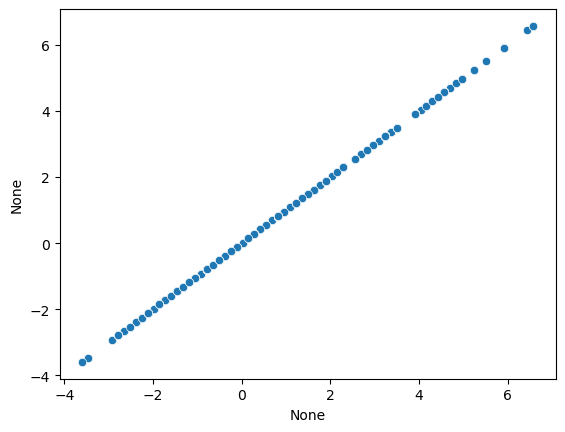

In [26]:
sns.scatterplot(x=even_series, y=full_series)

## Write temp data for all MG datasets

In [37]:
for test_data_afa in [
                     './../data/high_qual_alignments/alignments_to_backbone/Arthrobacter_adk_to_backbone.afa',
                     './../data/high_qual_alignments/alignments_to_backbone/Mycobacteria_adk_to_backbone.afa',
                     './../data/high_qual_alignments/alignments_to_backbone/Shah2024_adk_to_backbone.afa',
                     './../data/high_qual_alignments/alignments_to_backbone/Youngblut2020_adk_to_backbone.afa',
                     './../data/high_qual_alignments/alignments_to_backbone/Antarctic_adk_to_backbone.afa',
                     './../data/high_qual_alignments/alignments_to_backbone/Colman2024_adk_to_backbone.afa',
                     './../data/high_qual_alignments/alignments_to_backbone/Australia_adk_to_backbone.afa',
                     './../data/high_qual_alignments/alignments_to_backbone/Conteville2024_adk_to_backbone.afa',
                     './../data/high_qual_alignments/alignments_to_backbone/Mara2023_adk_to_backbone.afa',
                       './../data/high_qual_alignments/alignments_to_backbone/Salazar2019_adk_to_backbone.afa',
                    './../data/high_qual_alignments/alignments_to_backbone/RoyoLlonch2021_adk_to_backbone.afa'
                    ]:
    # # part 1: load data
    # # --------------------------------------------
    # pred_df_list = []
    # print(test_data_afa)
    # test_dataset = construct_msa_dataset(test_data_afa, ogt_parse_fn=lambda _str: _str)
    # print('Before removing training:',len(test_dataset))
    # test_dataset = [i for i in test_dataset if not i[0] in full_msa_keys]
    # print('After removing training:',len(test_dataset))

    dataset_name = test_data_afa.split('/')[-1].split('_adk_')[0]
    seq2envtemp = pd.read_csv(f'./../data/validation_datasets/{dataset_name}/md/{dataset_name}_env_temps.tsv', sep='\t').drop('Unnamed: 0', axis=1).set_index('protein')
    seq2envtemp['env temp'].rename('env_temp').to_csv(f'./../reference/v1_preprint/inputs/validation_datasets/{dataset_name}/md/{dataset_name}_temp_data.tsv', sep='\t')

In [42]:
ds = io.load_new_dataset('./../data/high_qual_alignments/alignments_to_backbone/Youngblut2020_adk_to_backbone.afa', scaler, exclude_ids = [i[0] for i in full_msa_dataset])

In [43]:
len(ds)

658

In [46]:
# [i[2]ds

## Test model params

In [47]:
model = reload_pickle('./../data/predictive_models/even_enetcv_ind.pickle')

In [49]:
print(model["best_model"][0].get_params()["precompute"])   # what v1 used
print(model["best_model"][0].coef_.dtype )

'auto'

In [50]:
import sklearn

In [51]:
sklearn.__version__

'1.4.1.post1'

## Working on context code

In [56]:
import tests

In [58]:
from roseate import context

In [64]:
sys.path.append('/data/mhoffert/fiererlab/adenylate_kinase_ogt/tests/test_initial_predict.py')

In [66]:

from test_initial_predict import MODEL, REF, SUPPORT, VALIDATION, path

In [71]:
even = io.reload_pickle('./../data/predictive_models/supporting_data/even_msa_dataset.pickle')
idx = context.load_legacy_context('/data/mhoffert/fiererlab/adenylate_kinase_ogt/data/esm_msa/c_w_e_context.pickle', even)
ref.assert_array_close(idx, "portable/esm_msa/c_w_e_context_indices.npy")
assert idx.shape == (len(corkrey), 8)

KeyError: 'NZ_JAEEGB010000020.1_21|RS_GCF_016316925.1|adk|temp=37.0|bitscore=201.9'

array([[328, 224,  99, 530, 346, 134, 853, 824]])

In [115]:
# contexts = reload_pickle('./../reference/v1_preprint/intermediates/esm_msa/even_full_context.pickle')
contexts = np.load(f"./../reference/v1_preprint/portable/esm_msa/even_full_context_indices.npy")[:1]

In [95]:
from roseate import embed

In [86]:
[[i[0] for i in even_msa_dataset].index(j[0]) for j in contexts[0]]

[328, 224, 99, 530, 346, 134, 853, 824]

In [105]:
model, _, batch_converter = embed.load_plm()

In [137]:
# ---------------------------------------------------------------- the one place to adapt
def embed_with_context(model, batch_converter, query, context_dataset, context_inds, layer=12):
    """
    Embed one (id, seq) query with an explicit list of (id, seq) context sequences.
    
    """
    print(context_inds)
    
    embeddings, _, _ = embed.get_embeddings(
        model=model, batch_converter=batch_converter, 
        data_to_embed=query, 
        context_dataset=context_dataset, 
        context_inds=context_inds,
        layer=layer, return_mean=False)
    return np.asarray(embeddings)

In [134]:
archived = np.load('./../reference/v1_preprint/portable/esm_msa/even_full_embeddings.npy')

In [135]:
archived.shape

(1227, 215, 768)

In [138]:
test_embedding = embed_with_context(model=model, batch_converter=batch_converter,  
                   query=[even_msa_dataset[0]], 
                   context_dataset=even, context_inds=contexts[:1])

[[328 224  99 530 346 134 853 824]]


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.13it/s]


In [139]:
test_embedding.shape

(1, 215, 768)

### for metagenomic dataset

In [142]:
archived = np.load('./../reference/v1_preprint/portable/validation_datasets/Antarctic/embeddings/Antarctic_full_even.npy')

In [143]:
archived.shape

(910, 215, 768)

In [144]:
msa = io.reload_pickle('./../reference/v1_preprint/intermediates/validation_datasets/Antarctic/embeddings/Antarctic_msa_dataset.pickle')

In [147]:
ctx = np.load('./../reference/v1_preprint/portable/validation_datasets/Antarctic/embeddings/Antarctic_even_context_values.npy')

In [146]:
len(msa)

910

In [148]:
test_embedding = embed_with_context(model=model, batch_converter=batch_converter,  
                   query=[msa[0]], 
                   context_dataset=even, context_inds=ctx[:1])

[[  27 1045  751  336  807  311 1198  762]]


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.14it/s]


In [149]:
test_embedding.shape

(1, 215, 768)

In [159]:
test_embedding[0, 0, :10]

array([-0.03309332,  0.06578152,  0.14660764,  0.1224219 , -0.47918153,
       -0.02003904, -0.26303533,  0.55730367, -0.15290444, -0.30085748],
      dtype=float32)

In [160]:
archived[0, 0, :10]

array([-0.03309332,  0.06578152,  0.14660764,  0.1224219 , -0.47918153,
       -0.02003904, -0.26303533,  0.55730367, -0.15290444, -0.30085748],
      dtype=float32)

In [162]:
archived[:10].shape

(10, 215, 768)

In [161]:
archived[0, 0, :10] == test_embedding[0, 0, :10]

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True])